# DHVC 검증 — Ng et al. (2017) 대비 정리판

수직 자연대류 채널(DHVC, Pr 0.7, 8H×4H×H)의 **최종 케이스 4개**만 보여 준다. 모두 mirror 벽 + 확장 통계 런이다.

| Ra | 런 | 통계 창 |
|---|---|---|
| 1e5 | value 벽 t=240 체크포인트 → mirror 재시작 | 270~450 (180 time) |
| 1e6 | 〃 | 270~450 (180 time) |
| 1e7 | 1e6 warm start → mirror | 100~200 (100 time) |
| 1e8 | 1e7(t=200) warm start → mirror, 4 GPU | 30~130 (100 time) |

참조: **PaScaL_TCS**(기존 기준, 주황 네모), **Ng 2017 DNS 점**(회색 마름모, 디지타이즈 ±3%), **Ng 2017 상관식**(검은 선).

구성 — §1 요약 표 · §2 Ra 스케일링(보정 축) · §3 시계열·수렴 · §4 평균장 · §5 rms·플럭스 · §6 조건평균(|Ri_f|) · §7 PDF·스펙트럼.
이전 런(value 벽·구 바이너리)은 `SHOW_LEGACY = True` 로 §2 에만 겹쳐 볼 수 있다. 예전 노트북 전체는 git 이력에 있다.

In [1]:
import glob, math, os, re
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

APP_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
REF_DIR = os.getcwd()

# ── 보여 줄 케이스 (Ra 순) ─────────────────────────────────────────────────
CASES = [
    dict(ra=1e5, log="logs/dhvc_1e5_ext_35997.log",       stats="out_1e5_ext"),
    dict(ra=1e6, log="logs/dhvc_1e6_ext_35998.log",       stats="out_1e6_ext"),
    dict(ra=1e7, log="logs/dhvc_1e7_mirror_35992.log",    stats="out_1e7_mirror"),
    dict(ra=1e8, log="logs/dhvc_1e8_4gpu_ext_35994.log",  stats="out_1e8_ext"),
]
# 이전 런 (value 벽 / 구 통계) — §2 에서 속 빈 회색 점으로만
SHOW_LEGACY = False
LEGACY = [
    dict(ra=1e5, stats="out_1e5"), dict(ra=1e6, stats="out_1e6"), dict(ra=1e7, stats="out_1e7"),
    dict(ra=1e8, stats="out_1e8_mirror"),
]

# ── 색: Ra 는 순서가 있는 크기라 한 색상(파랑)의 밝음→어두움 단계 ──────────────
RA_COLOR = {1e5: "#86b6ef", 1e6: "#3987e5", 1e7: "#1c5cab", 1e8: "#0d366b"}
REF_PASCAL = "#eb6834"     # PaScaL_TCS (참조 1)
REF_NG = "#7a7974"         # Ng 2017 DNS 점 (참조 2)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 8,
})
def ra_label(ra): return f"Ra = 1e{int(round(math.log10(ra)))}"

In [2]:
# ── 읽기 ──────────────────────────────────────────────────────────────────
def header_values(path):
    values, names = {}, []
    for line in open(path):
        if not line.startswith("#"): break
        for key, value in re.findall(r"(\w+)=([-\d.eE+]+)", line): values[key] = float(value)
        tokens = line[1:].split()
        if tokens and tokens[0] in ("z", "log10_Rif_center"): names = tokens
    return values, names

def read_table(path):
    values, names = header_values(path)
    data = np.loadtxt(path, comments="#")
    return values, {name: data[:, i] for i, name in enumerate(names[:data.shape[1]])}

def read_monitor(path):
    names, rows = None, []
    for line in open(path):
        if line.startswith("# step"): names = line[1:].split(); continue
        parts = line.split()
        if names and len(parts) == len(names) and not line.lstrip().startswith("#"):
            try: rows.append([float(x) for x in parts])
            except ValueError: pass
    data = np.array(rows)
    return {name: data[:, i] for i, name in enumerate(names)}

def read_spectra(path):
    values, _ = header_values(path)
    blocks, current = {"x": [], "y": []}, None
    for line in open(path):
        if line.startswith("# block x"): current = "x"; continue
        if line.startswith("# block y"): current = "y"; continue
        if line.startswith("#") or current is None: continue
        blocks[current].append([float(v) for v in line.split()])
    return values, {k: np.array(v) for k, v in blocks.items()}

def latest(folder, prefix):
    paths = sorted(glob.glob(os.path.join(APP_DIR, folder, f"{prefix}_*.dat")))
    return paths

runs = []
for case in CASES:
    stats_paths = latest(case["stats"], "dhvc_stats")
    if not stats_paths:
        print(f"[{ra_label(case['ra'])}] 통계 없음 — 건너뜀"); continue
    header, profile = read_table(stats_paths[-1])
    run = dict(case, header=header, profile=profile, monitor=read_monitor(os.path.join(APP_DIR, case["log"])),
               snapshots=[header_values(p)[0] for p in stats_paths], color=RA_COLOR[case["ra"]])
    conditional_paths, pdf_paths, spectra_paths = (latest(case["stats"], p) for p in
                                                   ("dhvc_conditional", "dhvc_richardson_pdf", "dhvc_spectra"))
    run["conditional"] = read_table(conditional_paths[-1]) if conditional_paths else None
    run["pdf"] = read_table(pdf_paths[-1]) if pdf_paths else None
    run["spectra"] = read_spectra(spectra_paths[-1]) if spectra_paths else None
    runs.append(run)
    print(f"[{ra_label(case['ra'])}] {os.path.basename(stats_paths[-1])}  창 t {header['t_start']:.0f}~{header['t']:.0f} "
          f"(sum_dt {header['sum_dt']:.0f})  조건평균 {'O' if run['conditional'] else '-'}  PDF {'O' if run['pdf'] else '-'}  "
          f"스펙트럼 {'O' if run['spectra'] else '-'}")

legacy = []
if SHOW_LEGACY:
    for case in LEGACY:
        paths = latest(case["stats"], "dhvc_stats")
        if paths: legacy.append(dict(case, header=header_values(paths[-1])[0]))

# ── 참조 ──────────────────────────────────────────────────────────────────
pascal = np.genfromtxt(os.path.join(REF_DIR, "PaScaL_TCS.csv"), delimiter=",")
def read_reference_csv(name):
    """'#' 주석 줄을 건너뛰고 첫 줄을 열 이름으로 읽는다 (숫자 열만)."""
    lines = [l for l in open(os.path.join(REF_DIR, name)) if l.strip() and not l.startswith("#")]
    names = lines[0].strip().split(",")
    rows = [l.strip().split(",") for l in lines[1:]]
    table = {}
    for i, n in enumerate(names):
        try: table[n] = np.array([float(r[i]) for r in rows])
        except ValueError: pass
    return table
ng_re = read_reference_csv("ng2017_fig10_re_dstar.csv")
ng_fig8 = read_reference_csv("ng2017_fig8.csv")
def pascal_re(ra): return float(np.exp(np.interp(np.log(ra), np.log(pascal[:, 0]), np.log(pascal[:, 1]))))
def ng_point(ra, table, column):
    hit = np.isclose(table["Ra"], ra, rtol=0.01)
    return float(table[column][hit][0]) if hit.any() else float("nan")
NG_RE = lambda ra: 0.23 * ra**0.28
NG_RE_LOW = lambda ra: 1.3 * ra**0.20
NG_NU = lambda ra: 0.0772 * ra**0.32
NG_RHO_52 = lambda ra: 0.49 * np.vectorize(math.erf)(0.35 * np.log10(ra) - 2.95) + 0.5
NG_RHO_53 = lambda ra: 0.99 * np.exp(-2.21 * np.exp(-0.48 * np.log10(ra) + 2.91))

[Ra = 1e5] dhvc_stats_00134995.dat  창 t 270~450 (sum_dt 180)  조건평균 O  PDF O  스펙트럼 O
[Ra = 1e6] dhvc_stats_00173449.dat  창 t 270~450 (sum_dt 180)  조건평균 O  PDF O  스펙트럼 O
[Ra = 1e7] dhvc_stats_00076150.dat  창 t 100~200 (sum_dt 100)  조건평균 O  PDF O  스펙트럼 O
[Ra = 1e8] dhvc_stats_00192056.dat  창 t 30~130 (sum_dt 100)  조건평균 O  PDF O  스펙트럼 O


## 1. 요약 표

편차는 (우리 − 참조)/참조. Nu·ρ·Re_δ*,low 는 뜨거운 벽과 차가운 벽의 평균.

In [3]:
def derived(run):
    h = run["header"]
    out = dict(re=h["Re_dstar"], nu=0.5 * (h["Nu_hot"] + h["Nu_cold"]))
    if run["conditional"]:
        ch, cp = run["conditional"]
        out["rho"] = 0.5 * (ch["rho_hot"] + ch["rho_cold"])
        out["nu_low"] = 0.5 * (ch["Nu_low_hot"] + ch["Nu_low_cold"]); out["nu_high"] = 0.5 * (ch["Nu_high_hot"] + ch["Nu_high_cold"])
        # 조건 Re_δ* (논문 eq. 6.x 와 같은 정의: 조건 평균속도 프로파일의 u_max·δ*/ν, 뜨거운 벽 쪽)
        values = []
        for side in ("hot", "cold"):
            z = cp["z"] if side == "hot" else 1.0 - cp["z"][::-1]
            u = cp[f"U_low_{side}"] if side == "hot" else -cp[f"U_low_{side}"][::-1]
            half = z < 0.5; z, u = z[half], u[half]
            k = int(np.argmax(u)); zc = np.concatenate(([0.0], z[:k + 1])); f = np.concatenate(([1.0], 1 - u[:k + 1] / u[k]))
            values.append(u[k] * np.trapezoid(f, zc) / h["nu"])
        out["re_low"] = float(np.mean(values))
    return out
for run in runs: run["derived"] = derived(run)

def pct(a, b): return f"{100 * (a / b - 1):+6.1f}%" if b == b and b else "     - "
print(f"{'Ra':>6} {'창(time)':>9} | {'Re_δ*':>6} {'PaScaL':>7} {'Ng점':>7} {'Ng식':>7} | {'Nu':>6} {'Ng식':>7} | "
      f"{'ρ':>5} {'Ng(5.2)':>8} | {'Re_δ*,l':>7} {'Ng식':>7}")
for run in runs:
    ra, d, h = run["ra"], run["derived"], run["header"]
    print(f"{ra:6.0e} {h['sum_dt']:9.0f} | {d['re']:6.2f} {pct(d['re'], pascal_re(ra))} {pct(d['re'], ng_point(ra, ng_re, 'Re_dstar'))} "
          f"{pct(d['re'], NG_RE(ra))} | {d['nu']:6.2f} {pct(d['nu'], NG_NU(ra))} | {d.get('rho', float('nan')):5.2f} "
          f"{float(NG_RHO_52(ra)):8.2f} | {d.get('re_low', float('nan')):7.1f} {pct(d.get('re_low', float('nan')), NG_RE_LOW(ra))}")

    Ra   창(time) |  Re_δ*  PaScaL     Ng점     Ng식 |     Nu     Ng식 |     ρ  Ng(5.2) | Re_δ*,l     Ng식
 1e+05       180 |   5.39   +0.3%   +2.7%   -6.7% |   3.03   -1.6% |  0.06     0.05 |    13.3   +2.5%
 1e+06       180 |  10.12   -3.0%      -    -8.1% |   6.58   +2.5% |  0.12     0.12 |    18.7   -9.4%
 1e+07       100 |  24.77   +8.0%      -   +18.1% |  13.46   +0.3% |  0.28     0.24 |    31.1   -4.6%
 1e+08       100 |  44.23   +2.6%   +3.8%  +10.7% |  27.78   -0.9% |  0.47     0.42 |    52.4   +1.3%


## 2. Ra 스케일링 — 보정 축

로그-로그 직선은 몇 % 차이를 숨기므로 **스케일링 지수로 나눈 보정 축**에 그린다(논문 fig.8·10 과 같은 방식). 상관식은 수평선이 된다.

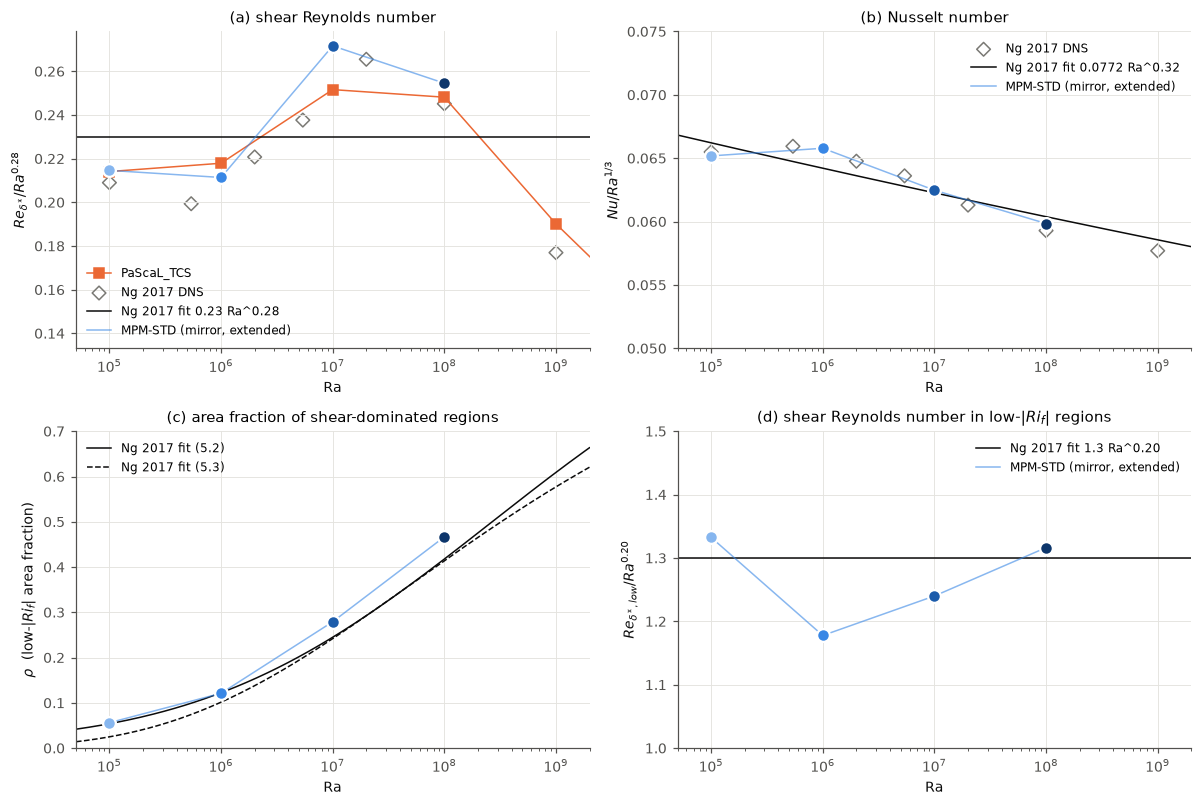

In [4]:
ras = np.array([r["ra"] for r in runs]); ra_line = np.logspace(4.7, 9.3, 200)
figure, axes = plt.subplots(2, 2, figsize=(11, 7.4))
def our_points(ax, values, scale):
    for run, value in zip(runs, values):
        ax.scatter(run["ra"], value / scale(run["ra"]), s=70, color=run["color"], edgecolor="white", linewidth=1.5, zorder=5)
    ax.plot(ras, np.array(values) / scale(ras), color="#3987e5", lw=1, alpha=0.6, zorder=4, label="MPM-STD (mirror, extended)")

# (a) Re_δ* / Ra^0.28
ax = axes[0, 0]; scale = lambda ra: ra**0.28
ax.plot(pascal[:, 0], pascal[:, 1] / scale(pascal[:, 0]), "s-", color=REF_PASCAL, ms=6, lw=1, label="PaScaL_TCS")
ax.scatter(ng_re["Ra"], ng_re["Re_dstar"] / scale(ng_re["Ra"]), marker="D", s=40, facecolor="none", edgecolor=REF_NG, label="Ng 2017 DNS")
ax.axhline(0.23, color=INK, lw=1, label="Ng 2017 fit 0.23 Ra^0.28")
our_points(ax, [r["derived"]["re"] for r in runs], scale)
for item in legacy: ax.scatter(item["ra"], item["header"]["Re_dstar"] / scale(item["ra"]), s=40, facecolor="none", edgecolor="0.6", label=None)
ax.set_ylabel(r"$Re_{\delta^*} / Ra^{0.28}$"); ax.set_title("(a) shear Reynolds number")
# (b) Nu / Ra^(1/3)
ax = axes[0, 1]; scale = lambda ra: ra**(1 / 3)
ax.scatter(ng_fig8["Ra"], ng_fig8["Nu"] / scale(ng_fig8["Ra"]), marker="D", s=40, facecolor="none", edgecolor=REF_NG, label="Ng 2017 DNS")
ax.plot(ra_line, NG_NU(ra_line) / scale(ra_line), color=INK, lw=1, label="Ng 2017 fit 0.0772 Ra^0.32")
our_points(ax, [r["derived"]["nu"] for r in runs], scale)
ax.set_ylabel(r"$Nu / Ra^{1/3}$"); ax.set_title("(b) Nusselt number")
# (c) ρ
ax = axes[1, 0]
ax.plot(ra_line, NG_RHO_52(ra_line), color=INK, lw=1, label="Ng 2017 fit (5.2)")
ax.plot(ra_line, NG_RHO_53(ra_line), color=INK, lw=1, ls="--", label="Ng 2017 fit (5.3)")
have = [r for r in runs if "rho" in r["derived"]]
for run in have: ax.scatter(run["ra"], run["derived"]["rho"], s=70, color=run["color"], edgecolor="white", linewidth=1.5, zorder=5)
ax.plot([r["ra"] for r in have], [r["derived"]["rho"] for r in have], color="#3987e5", lw=1, alpha=0.6)
ax.set_ylim(0, 0.7); ax.set_ylabel(r"$\rho$  (low-$|Ri_f|$ area fraction)"); ax.set_title("(c) area fraction of shear-dominated regions")
# (d) Re_δ*,low / Ra^0.2
ax = axes[1, 1]; scale = lambda ra: ra**0.20
ax.axhline(1.3, color=INK, lw=1, label="Ng 2017 fit 1.3 Ra^0.20")
our_points(ax, [r["derived"]["re_low"] for r in have], scale)
ax.set_ylabel(r"$Re_{\delta^*,low} / Ra^{0.20}$"); ax.set_title(r"(d) shear Reynolds number in low-$|Ri_f|$ regions")
for ax in axes.flat:
    ax.set_xscale("log"); ax.set_xlim(5e4, 2e9); ax.set_xlabel("Ra"); ax.legend(loc="best")
axes[0, 1].set_ylim(0.05, 0.075); axes[1, 1].set_ylim(1.0, 1.5)
figure.tight_layout(); plt.show()

## 3. 시계열 — 통계 창이 정상상태 안인가

열마다 Ra 하나. 파란 띠가 통계 누적 구간이다. 위: 순간 u_max (느린 진동이 보이면 창 길이가 중요하다). 가운데: 벽 Nu (두 벽 평균). 아래: 누적 Re_δ* — 마지막 값이 §1 표의 값이다.

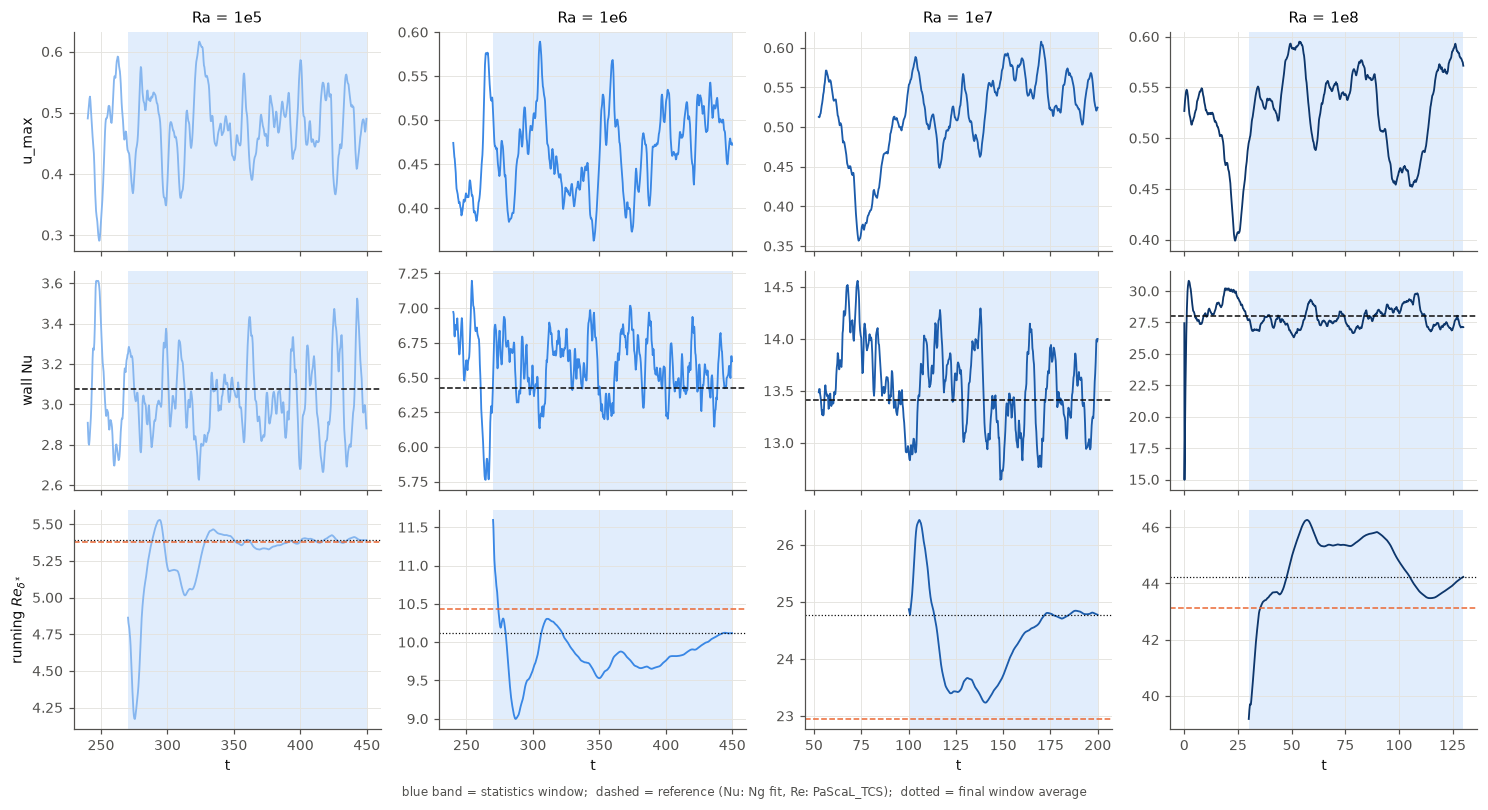

In [5]:
figure, axes = plt.subplots(3, len(runs), figsize=(3.4 * len(runs), 7.2), sharex="col")
for col, run in enumerate(runs):
    m, h = run["monitor"], run["header"]
    for row, (key, label) in enumerate([("u_max", "u_max"), ("Nu", "wall Nu"), ("Re_dstar", r"running $Re_{\delta^*}$")]):
        ax = axes[row, col]
        y = 0.5 * (m["Nu_hot"] + m["Nu_cold"]) if key == "Nu" else m[key]
        mask = (m["Re_dstar"] > 0) if key == "Re_dstar" else np.ones_like(y, bool)
        ax.axvspan(h["t_start"], h["t"], color="#cde2fb", alpha=0.6, lw=0)
        ax.plot(m["time"][mask], y[mask], color=run["color"], lw=1.2)
        if key == "Re_dstar":
            ax.axhline(pascal_re(run["ra"]), color=REF_PASCAL, lw=1, ls="--")
            ax.axhline(h["Re_dstar"], color=INK, lw=0.8, ls=":")
        if key == "Nu": ax.axhline(NG_NU(run["ra"]), color=INK, lw=1, ls="--")
        if col == 0: ax.set_ylabel(label)
        if row == 0: ax.set_title(ra_label(run["ra"]))
    axes[-1, col].set_xlabel("t")
figure.text(0.5, -0.01, "blue band = statistics window;  dashed = reference (Nu: Ng fit, Re: PaScaL_TCS);  dotted = final window average",
            ha="center", color=MUTED, fontsize=8)
figure.tight_layout(); plt.show()

## 4. 평균장 — 뜨거운 벽 쪽 (z < 0.5)

(a) 바깥 변수 U/u_max vs z/δ_max, (b) 벽 단위 u⁺(z⁺), (c) 온도 θ⁺ = (T_wall − T)/θ_τ, (d) 평균 온도 T(z). 차가운 벽은 반대칭이라 같은 그림이 된다.

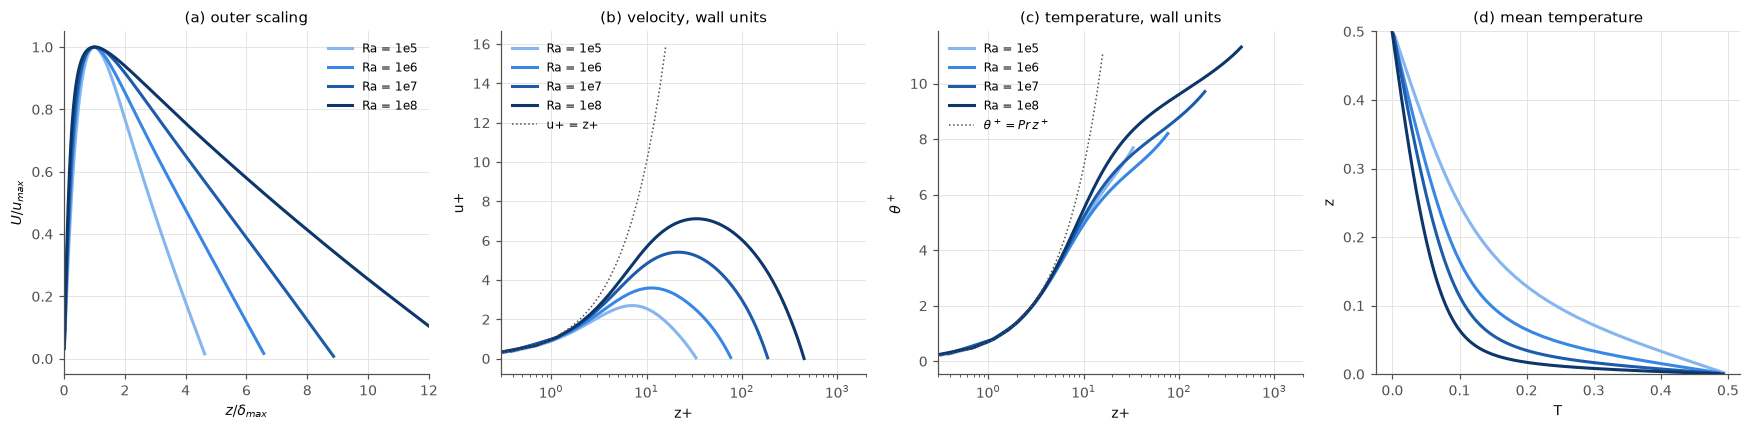

In [6]:
figure, axes = plt.subplots(1, 4, figsize=(16, 4))
for run in runs:
    p, h = run["profile"], run["header"]; half = p["z"] < 0.5
    z, U, T = p["z"][half], p["U"][half], p["T"][half]
    zp, up, tp = z * h["u_tau_hot"] / h["nu"], U / h["u_tau_hot"], (0.5 - T) / h["theta_tau_hot"]
    label = ra_label(run["ra"])
    axes[0].plot(z / h["delta_max"], U / h["u_max"], color=run["color"], label=label)
    axes[1].semilogx(zp, up, color=run["color"], label=label)
    axes[2].semilogx(zp, tp, color=run["color"], label=label)
    axes[3].plot(T, z, color=run["color"], label=label)
zl = np.logspace(-0.5, 1.2, 30)
axes[1].semilogx(zl, zl, color=MUTED, lw=1, ls=":", label="u+ = z+")
axes[2].semilogx(zl, 0.7 * zl, color=MUTED, lw=1, ls=":", label=r"$\theta^+ = Pr\,z^+$")
axes[0].set_xlim(0, 12); axes[0].set_xlabel(r"$z/\delta_{max}$"); axes[0].set_ylabel(r"$U/u_{max}$"); axes[0].set_title("(a) outer scaling")
axes[1].set_xlim(0.3, 2e3); axes[1].set_xlabel("z+"); axes[1].set_ylabel("u+"); axes[1].set_title("(b) velocity, wall units")
axes[2].set_xlim(0.3, 2e3); axes[2].set_xlabel("z+"); axes[2].set_ylabel(r"$\theta^+$"); axes[2].set_title("(c) temperature, wall units")
axes[3].set_ylim(0, 0.5); axes[3].set_xlabel("T"); axes[3].set_ylabel("z"); axes[3].set_title("(d) mean temperature")
axes[0].legend(); axes[1].legend(loc="upper left"); axes[2].legend(loc="upper left")
figure.tight_layout(); plt.show()

## 5. 변동량 — rms 와 난류 플럭스 (벽 단위, 뜨거운 벽 쪽)

u = 수직 상승 방향(주류), v = 스팬, w = 벽수직. 플럭스는 ⟨u′w′⟩⁺ 와 ⟨w′T′⟩/(u_τ θ_τ).

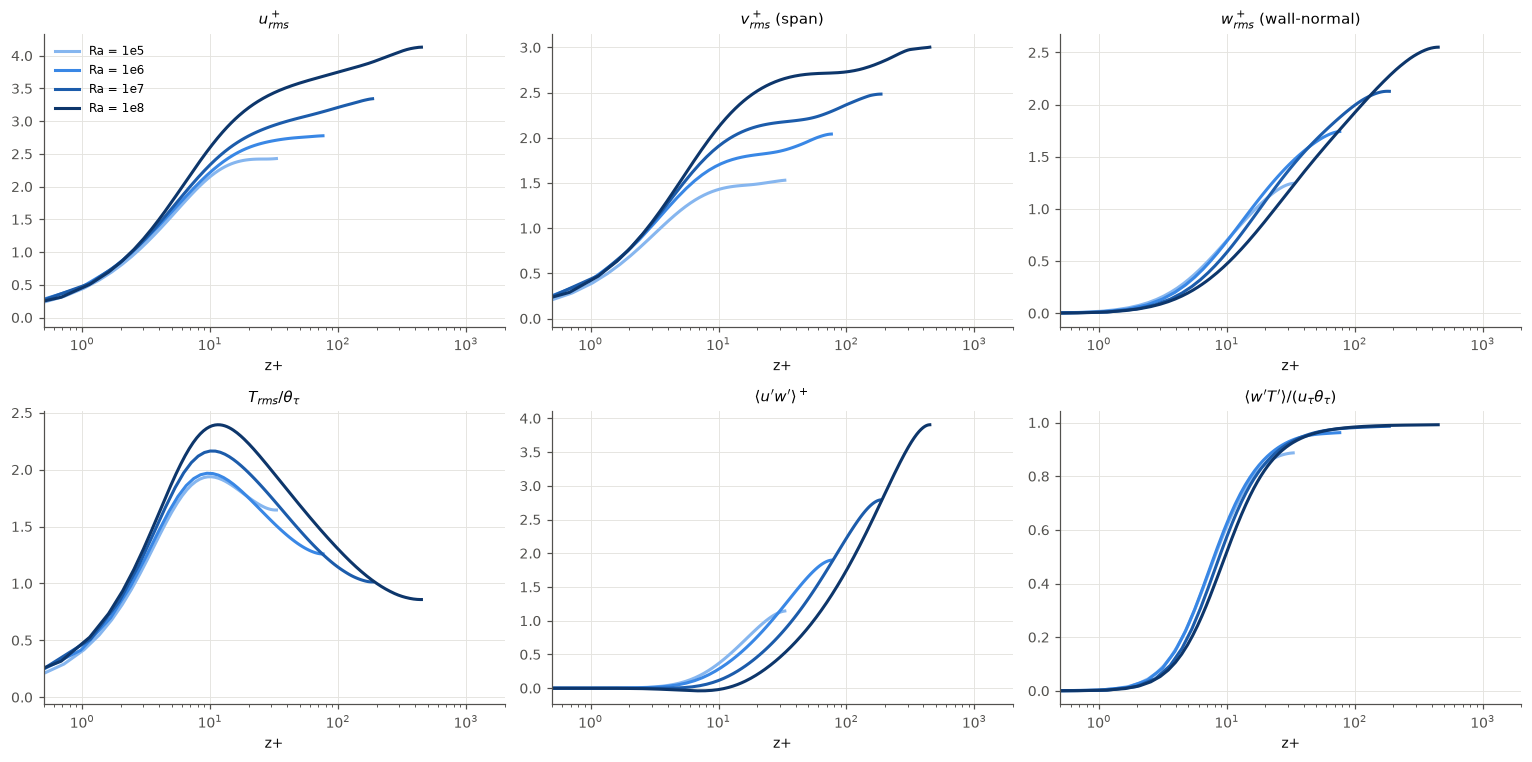

In [7]:
panels = [("urms", r"$u_{rms}^+$", "u"), ("vrms", r"$v_{rms}^+$ (span)", "u"), ("wrms", r"$w_{rms}^+$ (wall-normal)", "u"),
          ("trms", r"$T_{rms}/\theta_\tau$", "t"), ("uw", r"$\langle u'w'\rangle^+$", "uw"), ("wT", r"$\langle w'T'\rangle/(u_\tau\theta_\tau)$", "wt")]
figure, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (key, label, kind) in zip(axes.flat, panels):
    for run in runs:
        p, h = run["profile"], run["header"]; half = p["z"] < 0.5
        zp = p["z"][half] * h["u_tau_hot"] / h["nu"]
        scale = {"u": h["u_tau_hot"], "t": h["theta_tau_hot"], "uw": h["u_tau_hot"] ** 2,
                 "wt": h["u_tau_hot"] * h["theta_tau_hot"]}[kind]
        ax.semilogx(zp, p[key][half] / scale, color=run["color"], label=ra_label(run["ra"]))
    ax.set_xlim(0.5, 2e3); ax.set_xlabel("z+"); ax.set_title(label)
axes[0, 0].legend()
figure.tight_layout(); plt.show()

## 6. 조건평균 — 낮은 |Ri_f| (전단 지배) vs 높은 |Ri_f| (부력 지배), 뜨거운 벽

Ng 2017 §6: 벽 기둥마다 국소 |Ri_f| ≤ 0.1 이면 "low"(전단 지배 줄무늬)로 분류한다. **실선 = low, 점선 = high.** 벽 단위는 전체 평균 u_τ, θ_τ 로 정규화.
논문의 핵심은 low 영역이 high 보다 빠르고(전단 지배), Ra 와 함께 low 의 u⁺ 정점이 커지며 ρ 가 늘어난다는 것이다(Ra ≤ 1e8 에서는 아직 로그 영역이 없다).

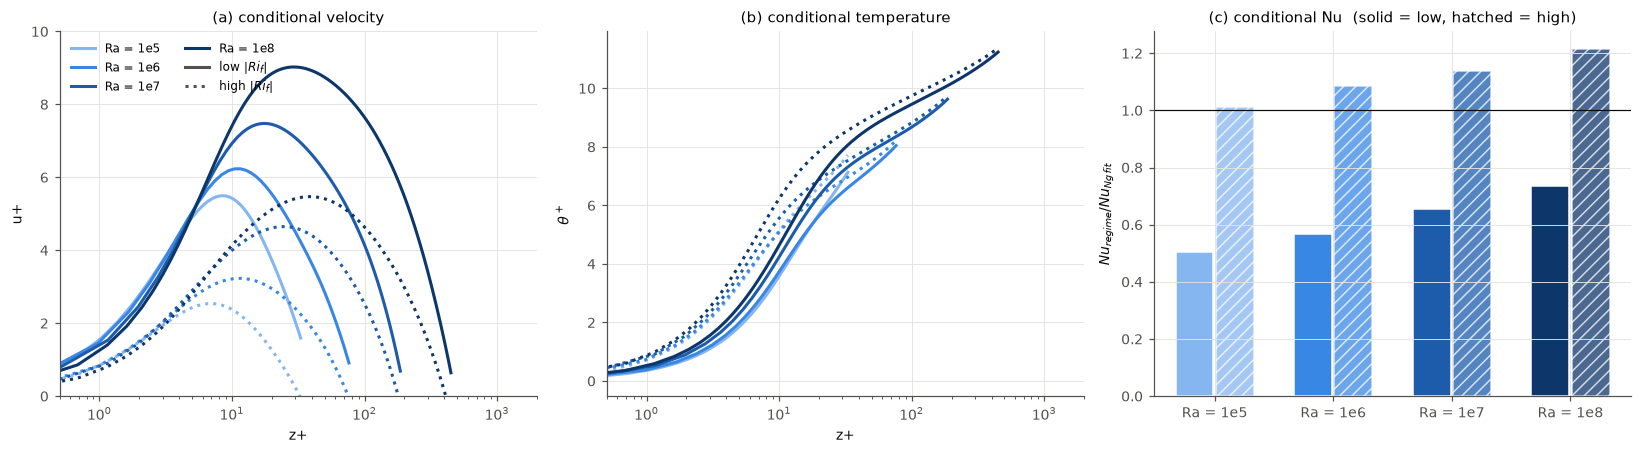

In [8]:
have = [r for r in runs if r["conditional"]]
figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for run in have:
    ch, cp = run["conditional"]; h = run["header"]; half = cp["z"] < 0.5
    zp = cp["z"][half] * h["u_tau_hot"] / h["nu"]
    for regime, ls in (("low", "-"), ("high", ":")):
        axes[0].semilogx(zp, cp[f"U_{regime}_hot"][half] / h["u_tau_hot"], color=run["color"], ls=ls,
                         label=ra_label(run["ra"]) if regime == "low" else None)
        axes[1].semilogx(zp, (0.5 - cp[f"T_{regime}_hot"][half]) / h["theta_tau_hot"], color=run["color"], ls=ls)
    axes[2].bar(np.log10(run["ra"]) - 0.17, 0.5 * (ch["Nu_low_hot"] + ch["Nu_low_cold"]) / NG_NU(run["ra"]), width=0.32,
                color=run["color"], edgecolor="white")
    axes[2].bar(np.log10(run["ra"]) + 0.17, 0.5 * (ch["Nu_high_hot"] + ch["Nu_high_cold"]) / NG_NU(run["ra"]), width=0.32,
                color=run["color"], edgecolor="white", hatch="///", alpha=0.75)
axes[0].plot([], [], color=MUTED, ls="-", label=r"low $|Ri_f|$"); axes[0].plot([], [], color=MUTED, ls=":", label=r"high $|Ri_f|$")
axes[0].set_xlim(0.5, 2e3); axes[0].set_ylim(0, 10); axes[0].set_xlabel("z+"); axes[0].set_ylabel("u+"); axes[0].legend(ncol=2)
axes[0].set_title("(a) conditional velocity")
axes[1].set_xlim(0.5, 2e3); axes[1].set_xlabel("z+"); axes[1].set_ylabel(r"$\theta^+$"); axes[1].set_title("(b) conditional temperature")
axes[2].axhline(1, color=INK, lw=0.8)
axes[2].set_xticks([np.log10(r["ra"]) for r in have]); axes[2].set_xticklabels([ra_label(r["ra"]) for r in have])
axes[2].set_ylabel(r"$Nu_{regime} / Nu_{Ng\,fit}$"); axes[2].set_title("(c) conditional Nu  (solid = low, hatched = high)")
figure.tight_layout(); plt.show()

## 7. |Ri_f| 분포와 에너지 스펙트럼

(a) 벽 기둥별 |Ri_f| 의 PDF (뜨거운 벽, log 축; 점선 = 분류 경계 0.1). (b~) 주류 방향 premultiplied 스펙트럼 k_x E_uu/u_τ² 를 z⁺–λ_x⁺ 평면에 — Ra 마다 한 칸, 같은 색 범위.

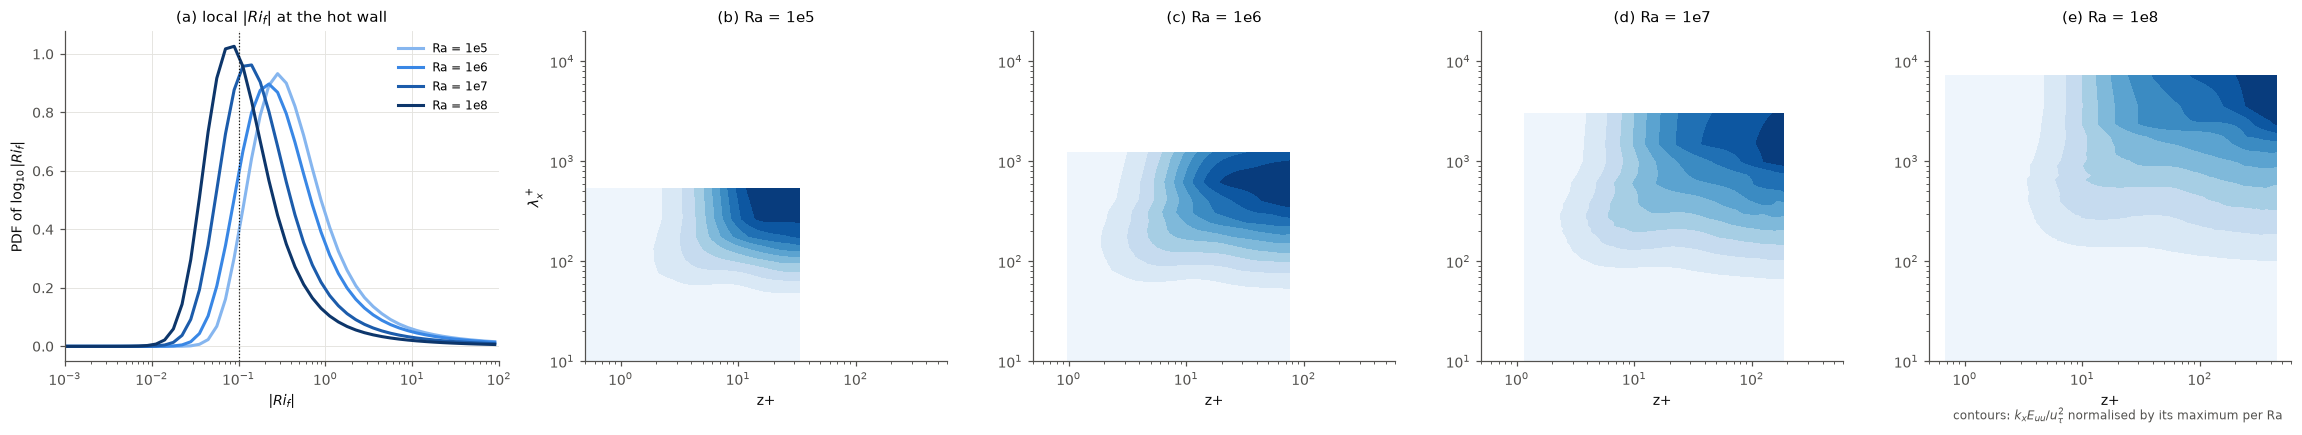

In [9]:
with_pdf = [r for r in runs if r["pdf"]]; with_spectra = [r for r in runs if r["spectra"]]
figure, axes = plt.subplots(1, 1 + len(with_spectra), figsize=(4.2 * (1 + len(with_spectra)), 3.9),
                            gridspec_kw={"width_ratios": [1.2] + [1] * len(with_spectra)})
ax = axes[0]
for run in with_pdf:
    ph, pp = run["pdf"]; x = pp["log10_Rif_center"]; width = x[1] - x[0]
    density = pp["count_hot"] / (pp["count_hot"].sum() * width)
    ax.plot(10 ** x, density, color=run["color"], label=ra_label(run["ra"]))
ax.axvline(0.1, color=INK, lw=0.8, ls=":")
ax.set_xscale("log"); ax.set_xlim(1e-3, 1e2); ax.set_xlabel(r"$|Ri_f|$"); ax.set_ylabel(r"PDF of $\log_{10}|Ri_f|$")
ax.set_title(r"(a) local $|Ri_f|$ at the hot wall"); ax.legend()
levels = np.linspace(0, 1, 11)
for ax, run in zip(axes[1:], with_spectra):
    sh, blocks = run["spectra"]; h = run["header"]; ex = blocks["x"]
    z, energy = ex[:, 0], ex[:, 2:]                    # m = 1.. (평균 제외)
    m = np.arange(1, energy.shape[1] + 1); kx = 2 * np.pi * m / sh["lx"]
    half = z < 0.5; zp = z[half] * h["u_tau_hot"] / h["nu"]; lam = 2 * np.pi / kx * h["u_tau_hot"] / h["nu"]
    pre = (kx[None, :] * energy[half] / (2 * np.pi / sh["lx"])) / h["u_tau_hot"] ** 2
    pre = pre / pre.max()
    ax.contourf(zp[1:], lam, pre[1:].T, levels=levels, cmap="Blues")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("z+"); ax.set_title(f"({'bcde'[with_spectra.index(run)]}) {ra_label(run['ra'])}")
    ax.set_xlim(0.5, 600); ax.set_ylim(10, 2e4); ax.grid(False)
axes[1].set_ylabel(r"$\lambda_x^+$")
figure.text(0.99, 0.01, r"contours: $k_x E_{uu}/u_\tau^2$ normalised by its maximum per Ra", ha="right", color=MUTED, fontsize=8)
figure.tight_layout(); plt.show()